# Tutorial 6 - Recurrent Neural Networks: RNN, LSTM and GRU

Course: Applied Deep Learning (ECE1553) - FALL 2026

Instructor: Dr. Ali Breyhi

Tutorial: Saleh Tabatabaei

CNNs exploit structure in **space**; recurrent networks exploit structure in **time**. Today we build an RNN, an LSTM and a GRU **from scratch**, train all three on the same forecasting task (predator–prey population dynamics), and compare them. Optional sections cover sequence classification, text generation and the practical tools PyTorch offers.

### Learning goals
1. Explain how an RNN processes a sequence with a hidden state and shared weights, and what *autoregressive* prediction means.
2. Implement RNN, LSTM and GRU cells and verify them against PyTorch's built-in cells.
3. Explain *why* plain RNNs struggle with long sequences (vanishing gradients) and how gates fix it.
4. Use `nn.RNN` / `nn.LSTM` / `nn.GRU` and read their input/output shapes.

> Each training run takes about 20–60 s. A GPU (`Runtime → Change runtime type`) helps, but the custom cells run step-by-step in Python, so the speed-up is modest.

---
## 0. Setup

In [ ]:
import time, random
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

np.random.seed(413)
torch.manual_seed(413)
random.seed(413)

EPOCHS = 41      # same as the original tutorial; use ~20 on a slow CPU
HIDDEN = 100     # hidden size used for RNN, LSTM and GRU so the comparison is fair
FAST = True      # only affects the optional sections at the end
results = {}     # test results of every model, compared at the end

def count_params(model):
    return sum(p.numel() for p in model.parameters())

In [ ]:
# ---- Helper functions for the Lotka-Volterra (predator-prey) data ----
def lv(x, t, params):
    dx = params[0] * x[0] - params[1] * x[0] * x[1]
    dy = params[2] * x[0] * x[1] - params[3] * x[1]
    return dx, dy

def lv_solve(tp, initial, params):
    return odeint(lv, initial, tp, args=((params,)))

def generate_lv_dataset(n, tp, i_range, p_range, noise_var=0.25):
    # Dataset is a list of trajectories. Each trajectory is a np array of shape (T, 2).
    dataset = []
    for _ in range(n):
        alpha = np.random.uniform(p_range[0][0], p_range[0][1])
        beta = np.random.uniform(p_range[1][0], p_range[1][1])
        delta = np.random.uniform(p_range[2][0], p_range[2][1])
        gamma = np.random.uniform(p_range[3][0], p_range[3][1])

        x = np.random.uniform(i_range[0][0], i_range[0][1])
        y = np.random.uniform(i_range[1][0], i_range[1][1])

        params = (alpha, beta, delta, gamma)
        traj = lv_solve(tp, (x, y), params)
        traj += np.random.randn(*traj.shape) * noise_var
        dataset.append(traj)
    return dataset

def visualize_lv(lv_tp, lv_data):
    fig, ax = plt.subplots(2, 2, figsize=(16, 6))
    for i in range(4):
        r, c = i // 2, i % 2
        ax[r][c].plot(lv_tp, lv_data[i][:, 0], label="prey")
        ax[r][c].plot(lv_tp, lv_data[i][:, 1], label="predator")
        ax[r][c].scatter(lv_tp, lv_data[i][:, 0], s=10)
        ax[r][c].scatter(lv_tp, lv_data[i][:, 1], s=10)
        ax[r][c].legend(loc="upper left")
    plt.tight_layout(); plt.show()

IRANGE = [[2, 4], [0.5, 1]]                                    # ranges of initial populations
PRANGE = [[0.35, 0.5], [0.15, 0.25], [0.05, 0.1], [0.25, 0.55]]  # ranges of alpha, beta, delta, gamma

---
## Part 1 — The task: time-series forecasting

Recurrent networks are used whenever the input or output is a **sequence**:

| Pattern | Example |
|---|---|
| many → one | sentiment of a review, classifying a heartbeat signal |
| many → many (same length) | tagging each word, denoising a signal |
| many → many (future) | **forecasting** ← today's task, translation |
| one → many | image captioning, music generation |

We observe the first part of a time series and must **predict the future**:

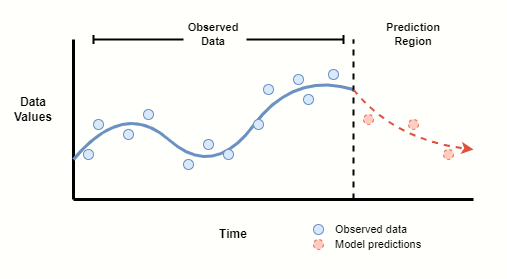

We use the RNN for **autoregressive prediction**. While data is available, we update the RNN normally:

$$y[t],\; h[t] = \text{RNNCell}(x[t],\, h[t-1])$$

In the prediction region there is no input, so the RNN is fed its **own previous output**:

$$y[t],\; h[t] = \text{RNNCell}(y[t-1],\, h[t-1])$$

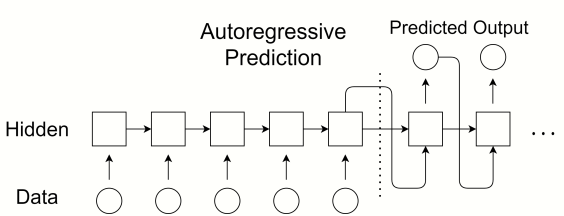

### Example: predator–prey relationships (Lotka–Volterra model)

$$ \begin{align}
\frac{dx}{dt} &= \alpha x - \beta x y \hspace{1em} [\text{prey}] \\
\frac{dy}{dt} &= \delta x y - \gamma y \hspace{1em} [\text{predator}]
\end{align}
$$

The parameters $\alpha, \beta, \delta, \gamma$ control reproduction and predation rates, and change the shape and frequency of the curves. To generate synthetic data we randomly sample the parameters, solve the equations, and add noise.

In [ ]:
lv_tp = np.linspace(0, 50, 50)
lv_data = generate_lv_dataset(1500, lv_tp, IRANGE, PRANGE, noise_var=0.25)

visualize_lv(lv_tp, lv_data)  # draw the first four trajectories in lv_data

Every trajectory is split **in time**:
- **Train region**: first 50% → the model *sees* this part
- **Validation region**: 50% to 75% → used to train and validate the forecasts
- **Test region**: 75% to 100% → never used for training

In [ ]:
plt.figure(figsize=(16, 4))

val_split = int(0.5 * len(lv_tp))
test_split = int(0.75 * len(lv_tp))

plt.plot(lv_tp[:val_split], lv_data[0][:val_split])
plt.plot(lv_tp[val_split:], lv_data[0][val_split:], ls="--")

plt.scatter(lv_tp[:test_split], lv_data[0][:test_split, 0])
plt.scatter(lv_tp[:test_split], lv_data[0][:test_split, 1])

plt.axvline(lv_tp[val_split])
plt.axvline(lv_tp[test_split])

plt.axvspan(lv_tp[val_split], lv_tp[test_split], color="yellow", alpha=0.2)
plt.axvspan(lv_tp[test_split], lv_tp[-1], color="red", alpha=0.2)

d_max = max(lv_data[0][:, 0]) + 1.5
plt.text(9, d_max, "Training Region", fontsize=16)
plt.text(31.5, d_max, "Validation\nPrediction Region", fontsize=16, ha="center")
plt.text(44, d_max, "Test\nPrediction Region", fontsize=16, ha="center")
plt.show()

💡 There are **two** splits. Each trajectory is cut into time regions (above), *and* the 1500 trajectories are divided into training / validation / test **sets**. The test score therefore measures forecasting on trajectories the model has never seen.

Let's prepare the data for PyTorch:

In [ ]:
class LVData(Dataset):
    def __init__(self, data, tp):
        self.data = data
        self.tp = tp

    def __getitem__(self, idx):
        traj = self.data[idx]

        # Individual trajectories are split into train/val/test regions
        val_split = int(0.5 * len(traj))
        test_split = int(0.75 * len(traj))

        train_traj = traj[:val_split]
        val_traj = traj[val_split:test_split]
        test_traj = traj[test_split:]

        train_tp = self.tp[:val_split]
        val_tp = self.tp[val_split:test_split]
        test_tp = self.tp[test_split:]

        return train_traj, val_traj, test_traj, train_tp, val_tp, test_tp

    def __len__(self):
        return len(self.data)

lv_data_tensor = torch.tensor(np.array(lv_data), dtype=torch.float32).to(device)
lv_tp_tensor = torch.tensor(lv_tp, dtype=torch.float32).to(device)

# Splitting trajectories into training / validation / test sets (81% / 9% / 10%)
perm = torch.randperm(len(lv_data_tensor))
n_test = int(0.1 * len(perm))
n_val = int(0.1 * (len(perm) - n_test))
lv_data_test = lv_data_tensor[perm[:n_test]]
lv_data_val = lv_data_tensor[perm[n_test:n_test + n_val]]
lv_data_train = lv_data_tensor[perm[n_test + n_val:]]

# Create PyTorch data structures
lv_train_set = LVData(lv_data_train, lv_tp_tensor)
lv_val_set = LVData(lv_data_val, lv_tp_tensor)
lv_test_set = LVData(lv_data_test, lv_tp_tensor)

lv_train_loader = DataLoader(lv_train_set, batch_size=32, shuffle=True)
lv_val_loader = DataLoader(lv_val_set, batch_size=256, shuffle=False)
lv_test_loader = DataLoader(lv_test_set, batch_size=256, shuffle=False)

print(f"{len(lv_train_set)} train / {len(lv_val_set)} val / {len(lv_test_set)} test trajectories")
batch = next(iter(lv_train_loader))
for name, t in zip(["train_region", "val_region", "test_region", "train_tp", "val_tp", "test_tp"], batch):
    print(f"{name:13s} {tuple(t.shape)}")

💡 Sequence batches have shape **(B, T, D)** = (batch size, time steps, features per step). Here D = 2 (prey and predator), the model sees T = 25 steps, and must forecast 12 (validation) + 13 (test) steps.

---
## Part 2 — RNN from scratch

### Why RNNs?
- A **hidden state** acts as memory, carrying information from earlier steps.
- The **same weights are shared across time**, so one model handles sequences of any length (just as a conv kernel is shared across space).
- The hidden-state update is non-linear, so the network can model complex dynamics.

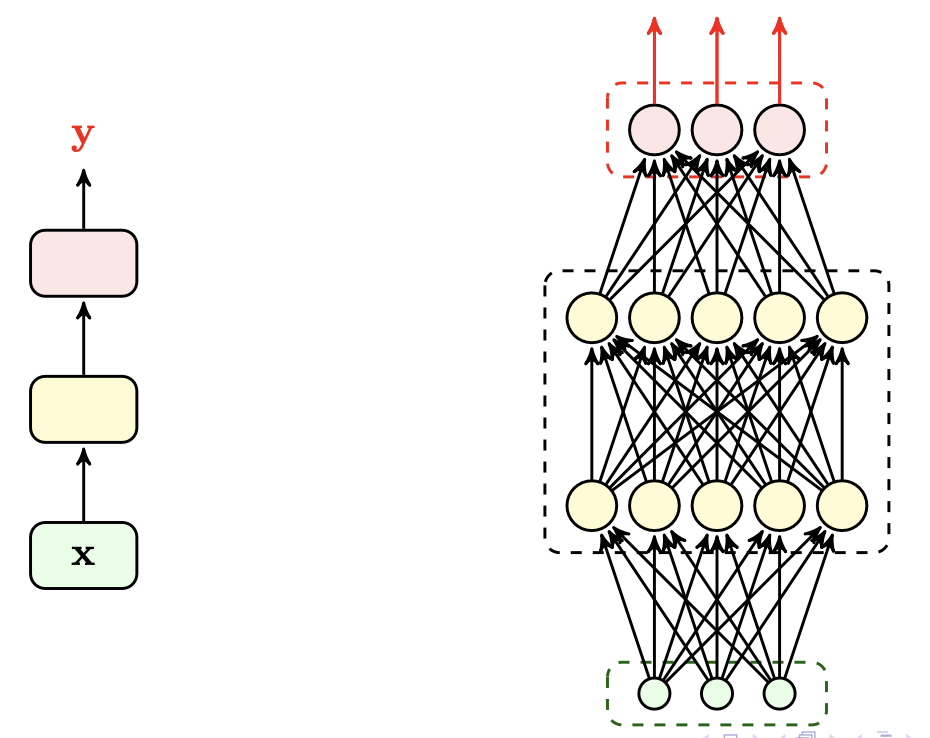

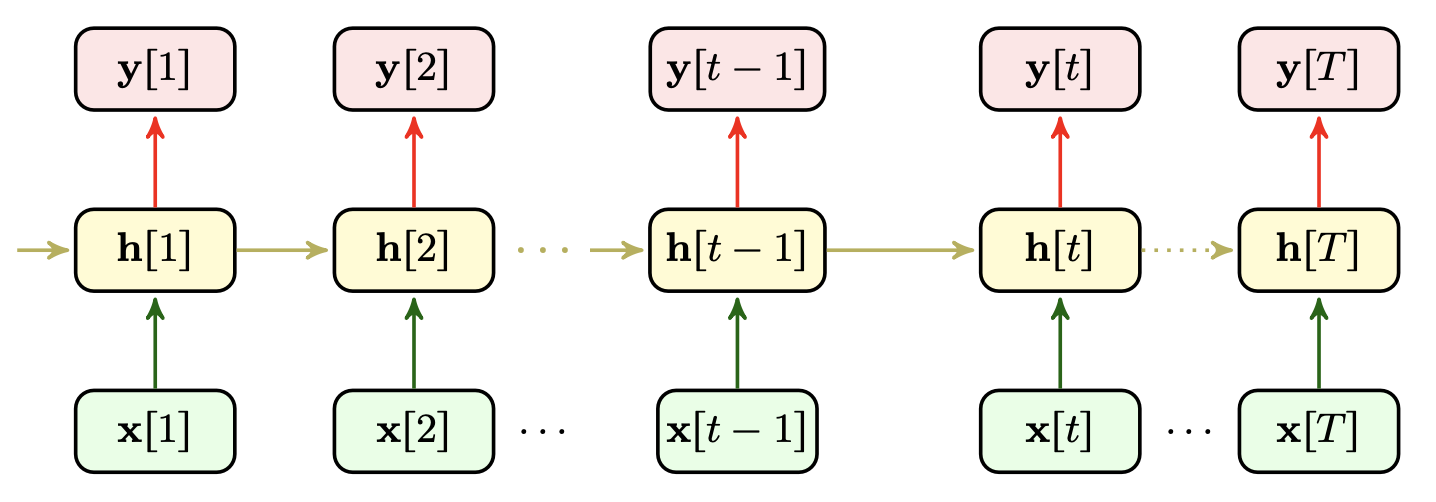

For a single point in time:

$$\begin{align}
h[t] &= \tanh\big(W_x\, x[t] + W_h\, h[t-1] + b\big) \\
y[t] &= W_y\, h[t] + b_y
\end{align}$$

The output layer is **linear** because this is regression. For classification you would add a softmax. The process starts at $t = 0$ with $h[0] = \mathbf{0}$ and runs for the length of the sequence.

Let's build one step first, $h[t] = \text{RNNCell}(x[t], h[t-1])$, and then the full RNN that loops over time.

In [ ]:
class SimpleRNNCell(nn.Module):
    def __init__(self, input_dim, hidden_dim):
        super(SimpleRNNCell, self).__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim

        # Weights for the input and hidden state
        self.W_x = nn.Linear(input_dim, hidden_dim)
        self.W_h = nn.Linear(hidden_dim, hidden_dim)

        # Activation function
        self.activation = nn.Tanh()

    def forward(self, x, h_prev):
        """
        x: Input at the current time step, shape (B, input_dim)
        h_prev: Hidden state from the previous time step, shape (B, hidden_dim)

        Returns:
        h_next: Updated hidden state, shape (B, hidden_dim)
        """
        h_next = self.activation(self.W_x(x) + self.W_h(h_prev))
        return h_next

In [ ]:
# 🧪 Is our cell the same as PyTorch's nn.RNNCell? Copy the weights over and compare.
our_cell, torch_cell = SimpleRNNCell(2, 4), nn.RNNCell(2, 4)      # nn.RNNCell uses tanh by default
with torch.no_grad():
    torch_cell.weight_ih.copy_(our_cell.W_x.weight); torch_cell.bias_ih.copy_(our_cell.W_x.bias)
    torch_cell.weight_hh.copy_(our_cell.W_h.weight); torch_cell.bias_hh.copy_(our_cell.W_h.bias)
x_t, h_prev = torch.randn(3, 2), torch.randn(3, 4)
print("identical:", torch.allclose(our_cell(x_t, h_prev), torch_cell(x_t, h_prev), atol=1e-6))

Now we build the full RNN module that applies this cell repeatedly, plus a `predict` method that implements **autoregressive** forecasting.

In [ ]:
class SimpleRNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(SimpleRNN, self).__init__()
        self.hidden_dim = hidden_dim
        self.rnn_cell = SimpleRNNCell(input_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        """
        x: Input sequence, shape (B, T, input_dim)

        Returns:
        outputs: Output for each time step, shape (B, T, output_dim)
        final_hidden: Final hidden state, shape (B, hidden_dim)
        """
        batch_size, seq_length, _ = x.size()
        h = self.init_hidden(batch_size).to(x.device)

        outputs = []
        for t in range(seq_length):
            h = self.rnn_cell(x[:, t, :], h)  # Get hidden state at current time step
            outputs.append(h.unsqueeze(1))    # Add a time dimension

        # Concatenate along the time dimension to get shape (B, T, hidden_dim)
        outputs = torch.cat(outputs, dim=1)

        # Map hidden states to output space for each time step
        outputs = self.output_layer(outputs)  # Shape (B, T, output_dim)
        return outputs, h

    def predict(self, x, K):
        """Autoregressive prediction of the next K steps (requires output_dim == input_dim)."""
        outputs, h = self.forward(x)
        pred = outputs[:, -1, :]               # prediction for the first unseen time step
        predictions = [pred.unsqueeze(1)]
        for _ in range(K - 1):
            h = self.rnn_cell(pred, h)         # feed our own prediction back in as the next input
            pred = self.output_layer(h)
            predictions.append(pred.unsqueeze(1))
        return torch.cat(predictions, dim=1)   # (B, K, output_dim)

    def init_hidden(self, batch_size):
        # The original tutorial used torch.randn here; zeros is the standard choice and makes
        # predictions deterministic (nn.RNN / nn.LSTM / nn.GRU also start from zeros).
        return torch.zeros((batch_size, self.hidden_dim))

rnn_model = SimpleRNN(input_dim=2, hidden_dim=HIDDEN, output_dim=2).to(device)
out, h_last = rnn_model(batch[0])
print("outputs:", tuple(out.shape), "| last hidden:", tuple(h_last.shape), "| 12-step forecast:", tuple(rnn_model.predict(batch[0], 12).shape))

🧪 **Quick check:** how many parameters does `SimpleRNNCell(2, 100)` have?

<details><summary>Answer</summary>

`W_x`: 2·100 + 100 = 300 and `W_h`: 100·100 + 100 = 10,100, so **10,400** in total. The count does **not** depend on the sequence length, because the weights are shared across time.
</details>

### Training
We train by **unrolling the forecast** over the validation region and minimising the mean squared error (MSE) between predicted and actual populations. Adaptive optimisers like Adam tend to work well for recurrent models. We also **clip the gradient norm**, the standard protection against *exploding* gradients in RNNs.

In [ ]:
def train_model(model, epochs=EPOCHS, lr=3e-4, n_steps=None, clip=1.0, log_every=10):
    """The training loop of the original tutorial, wrapped in a function so we can reuse it.
    n_steps: how many future steps the model must forecast during training (None = whole validation region)."""
    opt = Adam(model.parameters(), lr=lr)
    history = {"train": [], "val": []}
    start = time.time()

    for epoch in range(epochs):
        model.train()
        t_loss_sum = 0
        for batch in lv_train_loader:
            opt.zero_grad()
            train_region, val_region, _, train_tp, val_tp, _ = batch

            # Fit model on training region, predict in validation region
            k = len(val_region[0]) if n_steps is None else n_steps
            pred = model.predict(train_region, k)

            # Take a squared loss between predicted vs actual
            train_loss = nn.MSELoss()(pred, val_region[:, :k])
            train_loss.backward()
            if clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip)   # guard against exploding gradients
            opt.step()
            t_loss_sum += train_loss.item()

        # Validation: always forecast the whole validation region, without computing gradients
        model.eval()
        with torch.no_grad():
            v_loss_sum = 0
            for v_batch in lv_val_loader:
                train_region, val_region, _, train_tp, val_tp, _ = v_batch
                pred = model.predict(train_region, len(val_region[0]))
                v_loss_sum += nn.MSELoss()(pred, val_region).item()

        history["train"].append(t_loss_sum / len(lv_train_loader))
        history["val"].append(v_loss_sum / len(lv_val_loader))
        if epoch % log_every == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch}: Train Loss {history['train'][-1]:.4f}, Val Loss {history['val'][-1]:.4f}")

    print(f"done in {time.time() - start:.0f}s")
    return history

In [ ]:
def evaluate_test(model):
    """MSE on the test region of the test trajectories (forecast = val + test steps)."""
    model.eval()
    test_loss_sum = 0
    with torch.no_grad():
        for batch in lv_test_loader:
            train_region, val_region, test_region, train_tp, val_tp, test_tp = batch
            val_len, test_len = len(val_region[0]), len(test_region[0])

            # We can forecast arbitrarily far - here further than during training
            pred = model.predict(train_region, val_len + test_len)
            test_pred = pred[:, val_len:val_len + test_len]
            test_loss_sum += nn.MSELoss()(test_pred, test_region).item()
    return test_loss_sum / len(lv_test_loader)

def plot_prediction(model, title="", idx=0, ax=None):
    """Plot one test trajectory: observed part, ground truth (dots) and the model's forecast (dashed)."""
    model.eval()
    train_region, val_region, test_region, train_tp, val_tp, test_tp = next(iter(lv_test_loader))
    with torch.no_grad():
        pred = model.predict(train_region[idx:idx + 1], val_region.shape[1] + test_region.shape[1])[0].cpu()
    ground_truth = torch.cat([val_region[idx], test_region[idx]]).cpu()
    cat_tp = torch.cat([val_tp[idx], test_tp[idx]]).cpu()

    standalone = ax is None
    if standalone:
        ax = plt.figure(figsize=(10, 4)).gca()
    for d, (color, name) in enumerate([("tab:blue", "prey"), ("tab:orange", "predator")]):
        ax.plot(train_tp[idx].cpu(), train_region[idx, :, d].cpu(), color=color, label=f"{name} (observed)")
        ax.scatter(cat_tp, ground_truth[:, d], color=color, s=12)
        ax.plot(cat_tp, pred[:, d], "--", color=color, label=f"{name} (forecast)")
    ax.axvline(train_tp[idx, -1].item(), color="k", lw=0.8)
    ax.axvline(val_tp[idx, -1].item(), color="k", lw=0.8)
    d_max = max(ground_truth.max().item(), pred.max().item(), train_region[idx].max().item())
    for x_pos, label in [(9, "Training Region"), (29, "Val Region"), (42, "Test Region")]:
        ax.text(x_pos, d_max, label)
    ax.set_title(title or "Dots show ground truth. Dashed line shows model prediction")
    ax.legend(loc="upper left", fontsize=7)
    if standalone:
        plt.show()

In [ ]:
rnn_model = SimpleRNN(input_dim=2, hidden_dim=HIDDEN, output_dim=2).to(device)
rnn_history = train_model(rnn_model)

results["RNN"] = {"test_mse": evaluate_test(rnn_model), "params": count_params(rnn_model), "history": rnn_history}
print(f"RNN test MSE: {results['RNN']['test_mse']:.4f}")
plot_prediction(rnn_model, "Simple RNN forecast")

🧪 **Try it (later):** train without gradient clipping (`clip=None`) or with `lr=3e-3`. Does training become unstable?

---
## Part 3 — LSTM

### 3.1 Why do plain RNNs struggle? Vanishing gradients
Backpropagating through time multiplies by $\partial h[t]/\partial h[t-1] = \text{diag}(\tanh') \, W_h$ **once per time step**. If these factors are smaller than 1, the gradient shrinks *exponentially* with distance, and the network cannot learn long-range dependencies. If they are larger than 1, it explodes; that is why we clipped.

Let's measure it: how much does the **final** hidden state depend on the input at each earlier step $t$?

In [ ]:
def grad_norms_through_time(model, T=60, seed=0):
    """||d h_T / d x_t|| for every time step t of a random input sequence."""
    torch.manual_seed(seed)
    x = torch.randn(1, T, 2, requires_grad=True)
    out, state = model(x)
    h_last = state[0] if isinstance(state, tuple) else state   # LSTMs return (h, c)
    h_last.sum().backward()
    return x.grad[0].norm(dim=1).clamp(min=1e-30).detach()

g_rnn = grad_norms_through_time(SimpleRNN(2, 32, 2))
plt.figure(figsize=(8, 3.5))
plt.semilogy(g_rnn, label="simple RNN")
plt.xlabel("input time step t   (T = 60 is the end of the sequence)")
plt.ylabel("‖∂h_T / ∂x_t‖")
plt.title("Influence of early inputs on the final state decays exponentially")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### 3.2 The LSTM idea: a protected memory lane
*Long Short-Term Memory* (Hochreiter & Schmidhuber, 1997) adds a **cell state** $C_t$, a "conveyor belt" that is changed only by **element-wise** operations controlled by learned **gates**. Figures: Christopher Olah, [Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/).

![](https://colah.github.io/posts/2015-08-Understanding-LSTMs/img/LSTM3-chain.png)

**The cell state** runs straight through the chain with only minor linear interactions, so information can flow along it unchanged:

![](https://colah.github.io/posts/2015-08-Understanding-LSTMs/img/LSTM3-C-line.png)

**Why "gates"?** A sigmoid outputs values in $[0, 1]$; multiplying by it decides *how much* of each component lets through (0 = nothing, 1 = everything):

![](https://colah.github.io/posts/2015-08-Understanding-LSTMs/img/LSTM3-gate.png)

**Forget gate** $f_t$: what to erase from the memory.

![](https://colah.github.io/posts/2015-08-Understanding-LSTMs/img/LSTM3-focus-f.png)

**Input gate** $i_t$ and **candidate values** $\tilde{C}_t$: what new information to write.

![](https://colah.github.io/posts/2015-08-Understanding-LSTMs/img/LSTM3-focus-i.png)

**Updating the cell state**: forget some old memory and add some new.

![](https://colah.github.io/posts/2015-08-Understanding-LSTMs/img/LSTM3-focus-C.png)

**Output gate** $o_t$: which part of the memory to expose as the hidden state $h_t$.

![](https://colah.github.io/posts/2015-08-Understanding-LSTMs/img/LSTM3-focus-o.png)

### 3.3 Implementation
Each LSTM update (biases omitted):

$$ \begin{align}
f_t &= \sigma(W_{fi} x_t + W_{fh} h_{t-1}) \hspace{1em} [\text{Forget gate}] \\
i_t &= \sigma(W_{ii} x_t + W_{ih} h_{t-1}) \hspace{1em} [\text{Input gate}] \\
\tilde{C}_t &= \tanh(W_{gi} x_t + W_{gh} h_{t-1}) \hspace{1em} [\text{Update / candidate}] \\
o_t &= \sigma(W_{oi} x_t + W_{oh} h_{t-1}) \hspace{1em} [\text{Output gate}] \\
C_t &= C_{t-1} \odot f_t + i_t \odot \tilde{C}_t \\
h_t &= \tanh(C_t) \odot o_t
\end{align}
$$

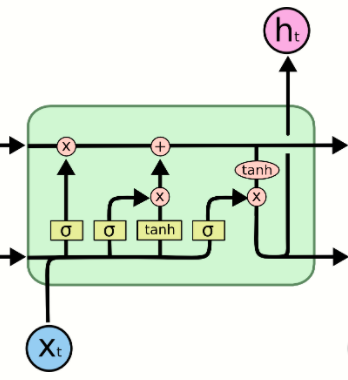

💡 The key line is $C_t = C_{t-1} \odot f_t + \dots$: the gradient along the cell state is multiplied by $f_t$, **not** by a weight matrix and a squashing derivative. When the network sets $f_t \approx 1$, the memory and its gradient survive for many steps.

In [ ]:
class OurLSTMCell(nn.Module):
    def __init__(self, in_dim, hid_dim, out_dim):
        super().__init__()
        self.forget_gate_i = nn.Linear(in_dim, hid_dim)
        self.forget_gate_h = nn.Linear(hid_dim, hid_dim)

        self.input_gate_i = nn.Linear(in_dim, hid_dim)
        self.input_gate_h = nn.Linear(hid_dim, hid_dim)

        self.update_gate_i = nn.Linear(in_dim, hid_dim)
        self.update_gate_h = nn.Linear(hid_dim, hid_dim)

        self.out_gate_i = nn.Linear(in_dim, hid_dim)
        self.out_gate_h = nn.Linear(hid_dim, hid_dim)

        self.sig = nn.Sigmoid()
        self.tanh = nn.Tanh()

    def forward(self, x, hid_state, cell_state):
        fg = self.sig(self.forget_gate_i(x) + self.forget_gate_h(hid_state))
        ig = self.sig(self.input_gate_i(x) + self.input_gate_h(hid_state))
        ug = self.tanh(self.update_gate_i(x) + self.update_gate_h(hid_state))
        og = self.sig(self.out_gate_i(x) + self.out_gate_h(hid_state))

        cell_state = cell_state * fg + ig * ug
        hid_state = og * self.tanh(cell_state)

        return hid_state, cell_state

In [ ]:
# 🧪 Same check as for the RNN: PyTorch stacks the 4 gates as rows [input | forget | candidate | output]
H = 4
our_cell, torch_cell = OurLSTMCell(2, H, 2), nn.LSTMCell(2, H)
with torch.no_grad():
    gates = [(our_cell.input_gate_i, our_cell.input_gate_h), (our_cell.forget_gate_i, our_cell.forget_gate_h),
             (our_cell.update_gate_i, our_cell.update_gate_h), (our_cell.out_gate_i, our_cell.out_gate_h)]
    for k, (lin_i, lin_h) in enumerate(gates):
        rows = slice(k * H, (k + 1) * H)
        torch_cell.weight_ih[rows] = lin_i.weight; torch_cell.bias_ih[rows] = lin_i.bias
        torch_cell.weight_hh[rows] = lin_h.weight; torch_cell.bias_hh[rows] = lin_h.bias
x_t, h_prev, c_prev = torch.randn(3, 2), torch.randn(3, H), torch.randn(3, H)
h1, c1 = our_cell(x_t, h_prev, c_prev)
h2, c2 = torch_cell(x_t, (h_prev, c_prev))
print("identical:", torch.allclose(h1, h2, atol=1e-6) and torch.allclose(c1, c2, atol=1e-6))

The LSTM iterates over time exactly like the RNN. The only difference is that the **cell state** must be initialised in addition to the hidden state.

In [ ]:
class OurLSTM(nn.Module):
    def __init__(self, in_dim, hid_dim, out_dim):
        super().__init__()
        self.in_dim = in_dim
        self.hid_dim = hid_dim
        self.out_dim = out_dim
        self.LSTMCell = OurLSTMCell(in_dim, hid_dim, out_dim)

    def forward(self, x):
        """
            X has shape B x T x D where
                B = Batch size
                T = Length of sequence
                D = Number of features
        """
        h = self.init_hidden(x.shape[0]).to(x.device)
        c = self.init_cell(x.shape[0]).to(x.device)

        out_arr = []
        # recurrent process
        for t in range(x.shape[1]):
            h, c = self.LSTMCell(x[:, t, :], h, c)
            out_arr.append(h.unsqueeze(1))

        return torch.cat(out_arr, dim=1), (h, c)

    def init_hidden(self, batch_size):
        return torch.zeros((batch_size, self.hid_dim))   # original: torch.randn

    # difference with simple RNN
    def init_cell(self, batch_size):
        return torch.zeros((batch_size, self.hid_dim))   # original: torch.randn

In [ ]:
class LSTMPredictor(nn.Module):
    def __init__(self, in_dim, hid_dim, out_dim=None):
        super().__init__()
        if out_dim is None:
            out_dim = in_dim

        self.out_net = nn.Linear(hid_dim, out_dim)
        self.lstm = OurLSTM(in_dim, hid_dim, out_dim)

    def forward(self, x):
        # The LSTM returns the output for each timestep in a (B x T x H) array.
        # The other output is a tuple of the final hidden and cell states.
        out, (h, c) = self.lstm(x)
        return out, (h, c)

    def predict(self, x, K):
        """
        Autoregressive prediction of K future steps.

        The last LSTM output (t = -1) is mapped by `out_net` to the prediction for the next
        time step, which is then fed back in as the next input. Repeat K times.
        (Fixed an off-by-one in the original: the first prediction is now included in the output.)
        """
        out, (h, c) = self.lstm(x)
        next_input = self.out_net(out[:, -1, :])         # (B, D): prediction for the first unseen step
        predictions = [next_input.unsqueeze(1)]

        for _ in range(K - 1):
            h, c = self.lstm.LSTMCell(next_input, h, c)
            next_input = self.out_net(h)
            predictions.append(next_input.unsqueeze(1))

        return torch.cat(predictions, dim=1)             # (B, K, D)

### 3.4 Do the gates really help the gradient?
We repeat the gradient experiment. The forget gate's **bias** controls how much the memory is kept: bias 0 → $f \approx \sigma(0) = 0.5$, bias 3 → $f \approx 0.95$. A trained LSTM *learns* this value. Many implementations initialise the forget bias to 1 for this reason.

In [ ]:
def lstm_with_forget_bias(bias, hidden=32):
    model = OurLSTM(2, hidden, 2)
    with torch.no_grad():
        model.LSTMCell.forget_gate_i.bias.fill_(bias)
        model.LSTMCell.forget_gate_h.bias.zero_()
    return model

plt.figure(figsize=(8, 3.5))
plt.semilogy(g_rnn, label="simple RNN")
plt.semilogy(grad_norms_through_time(lstm_with_forget_bias(0.0)), label="LSTM, forget bias 0  (f ≈ 0.5)")
plt.semilogy(grad_norms_through_time(lstm_with_forget_bias(3.0)), label="LSTM, forget bias 3  (f ≈ 0.95)")
plt.xlabel("input time step t"); plt.ylabel("‖∂h_T / ∂x_t‖")
plt.title("An open forget gate keeps early inputs 'visible' to the gradient")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.show()

🧪 **Quick check:** which gate values make the LSTM store a value *forever* and ignore all new inputs?

<details><summary>Answer</summary>

$f_t = 1$ (never forget) and $i_t = 0$ (never write). Then $C_t = C_{t-1}$ exactly.
</details>

### 3.5 Training & testing
Same training loop as for the RNN.

In [ ]:
lstm = LSTMPredictor(2, HIDDEN).to(device)
lstm_history = train_model(lstm)

results["LSTM"] = {"test_mse": evaluate_test(lstm), "params": count_params(lstm), "history": lstm_history}
print(f"LSTM test MSE: {results['LSTM']['test_mse']:.4f}")
plot_prediction(lstm, "LSTM forecast (dots: ground truth, dashed: prediction)")

---
## Part 4 — GRU and PyTorch's built-in layers

### 4.1 Gated Recurrent Unit (Cho et al., 2014)
The GRU simplifies the LSTM: there is **no separate cell state**, and it uses two gates instead of three.

$$ \begin{align}
r_t &= \sigma(W_{ri} x_t + W_{rh} h_{t-1}) \hspace{1em} [\text{Reset gate: how much of the past to use for the candidate}] \\
z_t &= \sigma(W_{zi} x_t + W_{zh} h_{t-1}) \hspace{1em} [\text{Update gate: keep old state vs. take the new one}] \\
n_t &= \tanh\big(W_{ni} x_t + r_t \odot (W_{nh} h_{t-1})\big) \hspace{1em} [\text{Candidate state}] \\
h_t &= (1 - z_t) \odot n_t + z_t \odot h_{t-1}
\end{align}
$$

💡 $z_t$ plays the role of *forget* and *input* gate at once: whatever share is kept from $h_{t-1}$ is not taken from $n_t$. When $z_t \approx 1$, the state is copied unchanged, which is the same "memory lane" trick as in the LSTM.

In [ ]:
class OurGRUCell(nn.Module):
    def __init__(self, in_dim, hid_dim):
        super().__init__()
        self.reset_gate_i = nn.Linear(in_dim, hid_dim)
        self.reset_gate_h = nn.Linear(hid_dim, hid_dim)

        self.update_gate_i = nn.Linear(in_dim, hid_dim)
        self.update_gate_h = nn.Linear(hid_dim, hid_dim)

        self.new_gate_i = nn.Linear(in_dim, hid_dim)
        self.new_gate_h = nn.Linear(hid_dim, hid_dim)

        self.sig = nn.Sigmoid()
        self.tanh = nn.Tanh()

    def forward(self, x, hid_state):
        rg = self.sig(self.reset_gate_i(x) + self.reset_gate_h(hid_state))
        zg = self.sig(self.update_gate_i(x) + self.update_gate_h(hid_state))
        ng = self.tanh(self.new_gate_i(x) + rg * self.new_gate_h(hid_state))
        return (1 - zg) * ng + zg * hid_state

# 🧪 Check against nn.GRUCell (gate order in PyTorch: [reset | update | new])
H = 4
our_cell, torch_cell = OurGRUCell(2, H), nn.GRUCell(2, H)
with torch.no_grad():
    gates = [(our_cell.reset_gate_i, our_cell.reset_gate_h), (our_cell.update_gate_i, our_cell.update_gate_h),
             (our_cell.new_gate_i, our_cell.new_gate_h)]
    for k, (lin_i, lin_h) in enumerate(gates):
        rows = slice(k * H, (k + 1) * H)
        torch_cell.weight_ih[rows] = lin_i.weight; torch_cell.bias_ih[rows] = lin_i.bias
        torch_cell.weight_hh[rows] = lin_h.weight; torch_cell.bias_hh[rows] = lin_h.bias
x_t, h_prev = torch.randn(3, 2), torch.randn(3, H)
print("identical:", torch.allclose(our_cell(x_t, h_prev), torch_cell(x_t, h_prev), atol=1e-6))

In [ ]:
class OurGRU(nn.Module):
    def __init__(self, in_dim, hid_dim):
        super().__init__()
        self.hid_dim = hid_dim
        self.GRUCell = OurGRUCell(in_dim, hid_dim)

    def forward(self, x):
        h = torch.zeros(x.shape[0], self.hid_dim, device=x.device)
        out_arr = []
        for t in range(x.shape[1]):
            h = self.GRUCell(x[:, t, :], h)
            out_arr.append(h.unsqueeze(1))
        return torch.cat(out_arr, dim=1), h


class GRUPredictor(nn.Module):
    def __init__(self, in_dim, hid_dim, out_dim=None):
        super().__init__()
        out_dim = out_dim or in_dim
        self.out_net = nn.Linear(hid_dim, out_dim)
        self.gru = OurGRU(in_dim, hid_dim)

    def forward(self, x):
        return self.gru(x)

    def predict(self, x, K):
        out, h = self.gru(x)
        next_input = self.out_net(out[:, -1, :])
        predictions = [next_input.unsqueeze(1)]
        for _ in range(K - 1):
            h = self.gru.GRUCell(next_input, h)
            next_input = self.out_net(h)
            predictions.append(next_input.unsqueeze(1))
        return torch.cat(predictions, dim=1)

gru = GRUPredictor(2, HIDDEN).to(device)
gru_history = train_model(gru)

results["GRU"] = {"test_mse": evaluate_test(gru), "params": count_params(gru), "history": gru_history}
print(f"GRU test MSE: {results['GRU']['test_mse']:.4f}")
plot_prediction(gru, "GRU forecast")

### 4.2 PyTorch's built-in recurrent layers
In practice you rarely write the loop yourself. `nn.RNN`, `nn.LSTM` and `nn.GRU` process the **whole sequence** in one call, using fast fused kernels (cuDNN) on GPUs. Their shapes are the main thing to remember:

In [ ]:
x = torch.randn(32, 25, 2)        # (B, T, D) because we use batch_first=True
layers = {"RNN": nn.RNN(2, HIDDEN, batch_first=True),
          "LSTM": nn.LSTM(2, HIDDEN, batch_first=True),
          "GRU": nn.GRU(2, HIDDEN, batch_first=True)}

for name, layer in layers.items():
    output, state = layer(x)
    if name == "LSTM":
        h_n, c_n = state
        state_txt = f"h_n {tuple(h_n.shape)}, c_n {tuple(c_n.shape)}"
    else:
        state_txt = f"h_n {tuple(state.shape)}"
    print(f"{name:4s} output {tuple(output.shape)} | {state_txt} | params {count_params(layer):,}")

- `output` holds the hidden state at **every** time step: (B, T, H). Use it for many-to-many tasks.
- `h_n` is the **last** hidden state with shape (num_layers × num_directions, B, H). Use it for many-to-one tasks.
- The LSTM additionally returns its cell state `c_n`.

🧪 **Quick check:** why does the LSTM have exactly 4× and the GRU 3× the parameters of the plain RNN?

<details><summary>Answer</summary>

Each gate (and the candidate) is a full "RNN-sized" pair of linear maps on $x_t$ and $h_{t-1}$. The LSTM has 4 of them (f, i, candidate, o), the GRU 3 (r, z, candidate), and the RNN 1.
</details>

---
## Wrap-up

In [ ]:
names = list(results)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in names:
    axes[0].plot(results[n]["history"]["val"], label=n)
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation MSE")
axes[0].set_title("Validation loss during training"); axes[0].legend()
axes[1].bar(names, [results[n]["test_mse"] for n in names], color=["tab:gray", "tab:blue", "tab:green", "tab:purple"][:len(names)])
axes[1].set_ylabel("test MSE (lower is better)"); axes[1].set_title("Forecast error on unseen trajectories")
plt.tight_layout(); plt.show()

print(f"{'model':8s} {'params':>8s} {'test MSE':>9s}")
for n in names:
    print(f"{n:8s} {results[n]['params']:>8,} {results[n]['test_mse']:>9.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (name, model) in zip(axes, [("RNN", rnn_model), ("LSTM", lstm), ("GRU", gru)]):
    plot_prediction(model, name, idx=1, ax=ax)
plt.tight_layout(); plt.show()

| | RNN | LSTM | GRU |
|---|---|---|---|
| State | $h_t$ | $h_t$ **and** cell $C_t$ | $h_t$ |
| Gates | none | forget, input, output | reset, update |
| Parameters (same H) | 1× | 4× | 3× |
| Long-range memory | poor (vanishing gradients) | good | good |
| Typical use | short sequences, teaching | default choice for long dependencies | often similar to LSTM; faster and smaller |

**Take-aways**
* An RNN is one small network applied at every time step; the **hidden state** carries information forward and the weights are **shared across time**.
* **Autoregressive** forecasting feeds the model's own predictions back as inputs, so errors can accumulate.
* Backpropagation through time multiplies many Jacobians, so gradients **vanish or explode**. Clipping fixes explosion; **gates** (LSTM/GRU) fix vanishing by giving the gradient an additive path.
* In practice, use `nn.LSTM` / `nn.GRU` with `batch_first=True` and mind the shapes of `output` vs `h_n`.

**Next lecture:** RNNs process tokens one at a time. *Attention* and **Transformers** let every position look at every other position directly.

---
# ⭐ Optional sections (homework)

## A. Play with short-sighted training
What if we train the model to predict only the next **two** time points? Does a model trained this way still capture the long-term pattern? This is the experiment from the original tutorial.

In [ ]:
lstm_short = LSTMPredictor(2, HIDDEN).to(device)
short_history = train_model(lstm_short, n_steps=2)      # <-- only 2 forecast steps during training

results["LSTM (2-step training)"] = {"test_mse": evaluate_test(lstm_short), "params": count_params(lstm_short),
                                     "history": short_history}
print(f"2-step-trained LSTM test MSE: {results['LSTM (2-step training)']['test_mse']:.4f}  "
      f"(full-horizon LSTM: {results['LSTM']['test_mse']:.4f})")
plot_prediction(lstm_short, "LSTM trained on 2-step forecasts, evaluated 25 steps ahead")

<details><summary>Discussion</summary>

During training the model only ever sees its own predictions for one step, so it never learns to recover from its own errors. At test time it is rolled out for 25 steps, and small errors compound (**exposure bias**). Training on longer rollouts, or mixing teacher forcing with free running (*scheduled sampling*), reduces this gap.
</details>

## B. Many-to-one: sequence classification on sequential MNIST
Read each MNIST image **row by row**: 28 time steps of 28 pixels. The LSTM must remember strokes from the top of the image to classify the digit at the bottom. This reuses the MNIST files from the CNN class: put them next to the notebook, or let torchvision download them.

In [ ]:
import os, shutil
from torchvision import datasets, transforms
from torch.utils.data import Subset

RAW = os.path.join("data", "MNIST", "raw"); os.makedirs(RAW, exist_ok=True)
for name in ["train-images-idx3-ubyte", "train-labels-idx1-ubyte", "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]:
    for ext in ["", ".gz"]:
        if os.path.exists(name + ext) and not os.path.exists(os.path.join(RAW, name + ext)):
            shutil.copy(name + ext, RAW)

tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
mnist_train = datasets.MNIST("data", train=True, download=True, transform=tf)
mnist_test = datasets.MNIST("data", train=False, download=True, transform=tf)
if FAST:
    mnist_train = Subset(mnist_train, torch.randperm(len(mnist_train))[:20000].tolist())
seq_train_loader = DataLoader(mnist_train, batch_size=128, shuffle=True)
seq_test_loader = DataLoader(mnist_test, batch_size=512)

class SeqMNISTClassifier(nn.Module):
    def __init__(self, cell="LSTM", hidden=128):
        super().__init__()
        rnn_cls = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        self.rnn = rnn_cls(input_size=28, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 10)

    def forward(self, x):                 # x: (B, 1, 28, 28)
        seq = x.squeeze(1)                # (B, T=28 rows, D=28 pixels)
        out, _ = self.rnn(seq)
        return self.fc(out[:, -1])        # many-to-one: classify from the LAST hidden state

def train_seq_classifier(cell, epochs=2 if FAST else 5):
    model = SeqMNISTClassifier(cell).to(device)
    opt = Adam(model.parameters(), lr=1e-3)
    for epoch in range(epochs):
        model.train()
        for xb, yb in seq_train_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
    model.eval(); correct = 0
    with torch.no_grad():
        for xb, yb in seq_test_loader:
            correct += (model(xb.to(device)).argmax(1) == yb.to(device)).sum().item()
    return 100 * correct / len(mnist_test)

for cell in ["RNN", "LSTM", "GRU"]:
    start = time.time()
    print(f"{cell:4s} test accuracy: {train_seq_classifier(cell):.2f}%  ({time.time() - start:.0f}s)")

🧪 Make the task harder by feeding the image **pixel by pixel** (784 time steps, 1 feature). The plain RNN typically collapses while the LSTM/GRU can still learn, which is a direct demonstration of long-range dependencies. Expect slow training.

## C. Character-level text generation (many-to-many)
A GRU language model reads text one character at a time and predicts the next character. Sampling from it generates new text. We use the *Tiny Shakespeare* corpus from Karpathy's char-rnn repository, with a small built-in fallback if there is no internet.

In [ ]:
import urllib.request
try:
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    text = urllib.request.urlopen(url, timeout=10).read().decode("utf-8")
except Exception:
    text = ("Recurrent networks read one symbol at a time and carry a memory of what came before. "
            "Gates decide what to keep, what to forget and what to reveal. ") * 300
if FAST:
    text = text[:300_000]

chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
print(f"{len(text):,} characters, vocabulary of {len(chars)}")

class CharRNN(nn.Module):
    def __init__(self, vocab, emb=64, hidden=256):
        super().__init__()
        self.embed = nn.Embedding(vocab, emb)                 # character id -> vector
        self.gru = nn.GRU(emb, hidden, batch_first=True)
        self.head = nn.Linear(hidden, vocab)                  # hidden state -> scores for the next character

    def forward(self, idx, h=None):
        out, h = self.gru(self.embed(idx), h)
        return self.head(out), h

def get_batch(B=64, T=100):
    ix = torch.randint(0, len(data) - T - 1, (B,))
    x = torch.stack([data[i:i + T] for i in ix])
    y = torch.stack([data[i + 1:i + T + 1] for i in ix])       # target = input shifted by one character
    return x.to(device), y.to(device)

@torch.no_grad()
def sample(model, start="ROMEO:", n=300, temperature=0.8):
    model.eval()
    idx = torch.tensor([[stoi.get(c, 0) for c in start]], device=device)
    logits, h = model(idx)
    result = start
    for _ in range(n):
        probs = F.softmax(logits[:, -1] / temperature, dim=-1)
        nxt = torch.multinomial(probs, 1)
        result += itos[nxt.item()]
        logits, h = model(nxt, h)                              # carry the hidden state forward
    return result

char_model = CharRNN(len(chars)).to(device)
opt = Adam(char_model.parameters(), lr=3e-3)
steps = 600 if FAST else 3000
for step in range(steps + 1):
    char_model.train()
    xb, yb = get_batch()
    logits, _ = char_model(xb)
    loss = F.cross_entropy(logits.reshape(-1, len(chars)), yb.reshape(-1))
    opt.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(char_model.parameters(), 1.0)
    opt.step()
    if step % 200 == 0:
        print(f"step {step}: loss {loss.item():.3f}")

print("\n" + sample(char_model))

🧪 Try temperatures 0.3 vs 1.2, and swap `nn.GRU` for `nn.LSTM` (remember that it returns `(h, c)`).

## D. Practical tools: stacked & bidirectional layers, variable-length sequences, speed

In [ ]:
# Stacked + bidirectional LSTM: shapes
lstm2 = nn.LSTM(input_size=2, hidden_size=16, num_layers=2, bidirectional=True, batch_first=True)
output, (h_n, c_n) = lstm2(torch.randn(8, 25, 2))
print("output:", tuple(output.shape), "  <- forward and backward states concatenated: 2 * 16")
print("h_n:   ", tuple(h_n.shape), "     <- num_layers * num_directions = 4")

# Variable-length sequences: pad them to one tensor, then "pack" so the LSTM skips the padding
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
seqs = [torch.randn(5, 2), torch.randn(3, 2), torch.randn(1, 2)]
lengths = torch.tensor([len(s) for s in seqs])
padded = pad_sequence(seqs, batch_first=True)                       # (3, 5, 2), zero-padded
small_lstm = nn.LSTM(2, 4, batch_first=True)
packed = pack_padded_sequence(padded, lengths, batch_first=True, enforce_sorted=False)
packed_out, (h_n, c_n) = small_lstm(packed)
out, _ = pad_packed_sequence(packed_out, batch_first=True)
last_valid = out[torch.arange(len(seqs)), lengths - 1]               # state at each sequence's true last step
print("h_n equals the state at each sequence's real end:", torch.allclose(h_n[0], last_valid, atol=1e-6))

# Speed: our Python loop vs. the fused built-in layer
xb = torch.randn(256, 100, 2, device=device)
ours, builtin = OurLSTM(2, HIDDEN, 2).to(device), nn.LSTM(2, HIDDEN, batch_first=True).to(device)
for name, m in [("our loop", ours), ("nn.LSTM", builtin)]:
    with torch.no_grad():
        m(xb)                                                        # warm-up
        if device.type == "cuda": torch.cuda.synchronize()
        start = time.time()
        for _ in range(5):
            m(xb)
        if device.type == "cuda": torch.cuda.synchronize()
    print(f"{name:9s} {(time.time() - start) / 5 * 1000:7.1f} ms per forward pass")

### More homework ideas
1. Add a **teacher-forcing** loss on the observed region (predict $x[t+1]$ from $x[\le t]$) to `train_model` and compare convergence speed.
2. Make the forecasting harder: fewer observed steps, more noise (`noise_var=0.5`), or a longer test horizon.
3. Initialise the LSTM forget-gate bias to 1 and compare training curves.
4. Replace `OurLSTM` inside `LSTMPredictor` with `nn.LSTM` + `nn.LSTMCell` for the rollout. How much faster is training?

### References
* Elman (1990). *Finding structure in time.* (simple RNN)
* Bengio, Simard & Frasconi (1994). *Learning long-term dependencies with gradient descent is difficult.*
* Hochreiter & Schmidhuber (1997). *Long short-term memory.*
* Cho et al. (2014). *Learning phrase representations using RNN encoder–decoder for statistical machine translation.* (GRU)
* Pascanu, Mikolov & Bengio (2013). *On the difficulty of training recurrent neural networks.* (gradient clipping)
* Olah (2015). [Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/)
* Karpathy (2015). [The Unreasonable Effectiveness of Recurrent Neural Networks](https://karpathy.github.io/2015/05/21/rnn-effectiveness/)